# Exercise 2

In [3]:
# import automatic differentiator to compute gradient module
import numpy as np
from autograd import grad 
from numpy.linalg import norm

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def normalized_gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval / (norm(grad_eval)+1e-8)
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return cost_history

# import automatic differentiator to compute gradient module
from autograd import grad 

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return cost_history

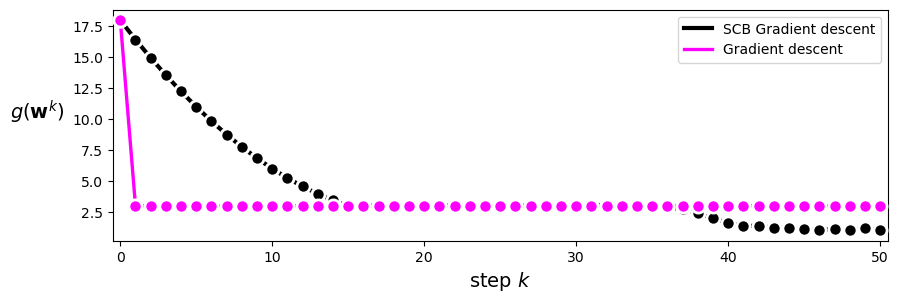

In [4]:
import autograd.numpy as anp

# defining g
g = lambda w: anp.tanh(4*w[0] + 4*w[1]) + anp.maximum(1.0, 4*(w[0])**2) + 1.0

# parameters
alpha = 0.1
w0 = np.array([2.0, 2.0])
max_its = 50

# cost histories
cost_history_SCBGD = normalized_gradient_descent(g,alpha,max_its,w0)
cost_history_GD = gradient_descent(g,alpha,max_its,w0)

# plot
from MLRPlotting import static_plotter
# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history_SCBGD, cost_history_GD],start=0,points=True,labels=[r'SCB Gradient descent', r'Gradient descent'])

The normal gradient descent decreses faster and end up stuck 

The normalized gradient descent deacreses slower but it is closer to the minimum of the function g.

For function with vanishing gradient, the normalized approach is more efficient.
